# A Distributed Representation of Temporal Context

Howard & Kahana (2002)

Run the setup cell, then run the cells below to use the interactive figures.

In [1]:
# @title Setup
import importlib.util, subprocess, sys
from pathlib import Path
packages = {'numpy': 'numpy', 'torch': 'torch', 'matplotlib': 'matplotlib', 'pandas': 'pandas', 'scipy': 'scipy', 'ipywidgets': 'ipywidgets'}
missing = [package for module, package in packages.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p/'notebooks/tcm2002/tcm.py').is_file()), None)
if ROOT is None:
    ROOT = Path.cwd()/'papers'
    if not (ROOT/'notebooks/tcm2002/tcm.py').is_file():
        if ROOT.exists():
            raise RuntimeError('The papers directory exists but is not this repository.')
        subprocess.check_call(['git', 'clone', '--depth', '1',
                              'https://github.com/h4ch1m1/complementary-learning-systems.git', str(ROOT)])
sys.path.insert(0, str(ROOT/'notebooks/tcm2002'))
import numpy as np
import torch
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display, SVG
from tcm import Parameters, TemporalContextModel, study_list, transition_distribution, expected_lag_crp
try:
    from google.colab import output
    output.enable_custom_widget_manager()
except ImportError:
    pass
torch.set_num_threads(1)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
PAPER = Parameters(beta=.402, gamma=1., tau=.247, distractor_duration=7.24)
WORDS = ['apple', 'river', 'key', 'tiger', 'umbrella', 'train', 'candle', 'forest', 'cup', 'moon', 'shoe', 'piano']
BLUE, GREY = '#3675a8', '#8a8f94'
TITLES = {'immediate': 'Immediate recall', 'delayed': 'Delayed recall', 'continuous': 'Continuous distractor'}
sys.path.insert(0, str(ROOT/'notebooks'))
import paper_figures as figures


In [2]:
# @title Figure helpers
class FigureView:
    def __init__(self):
        self.handle = None

    def show(self, fig):
        fig.tight_layout()
        if self.handle is None:
            self.handle = display(fig, display_id=True)
        else:
            self.handle.update(fig)
        plt.close(fig)

def word_bars(ax, values, title, color=BLUE, upper=1):
    ax.bar(range(12), np.asarray(values), color=color)
    ax.set(title=title, xticks=range(12), xticklabels=WORDS, ylim=(0, upper))
    ax.tick_params(axis='x', labelsize=9)

def context_strip(ax, context):
    values = np.r_[float(context[12]), context[:12].numpy()]
    labels = ['Initial', *WORDS]
    rest = float(context[13:].norm())
    if rest > 1e-12:
        values = np.r_[values, rest]
        labels.append('Math')
    ax.imshow(values[None, :], cmap='Blues', vmin=0, vmax=1, aspect='auto')
    ax.set(title='Current context', xticks=range(len(labels)), xticklabels=labels, yticks=[])
    ax.tick_params(axis='x', length=0, labelsize=9)
    for spine in ax.spines.values():
        spine.set_visible(False)

def predict(condition, params=PAPER):
    model, _ = study_list(condition, params)
    first, second = transition_distribution(model, suppress_repeats=True)
    lags, crp, _, _ = expected_lag_crp(first, second)
    return first.numpy(), lags.numpy(), crp.numpy()

## Introduction

<p>Episodic memory lets us remember when something happened and what happened alongside it. A classic way to study this is free recall: participants study a list of words, then report the words they remember in any order. The order they choose reveals how memory organizes experiences in time.</p>

<p>Two patterns often appear in these experiments. Recall tends to begin near the end of the list, the <em>recency effect</em>. After one word is recalled, the next often comes from a nearby position, the <em>contiguity effect</em>. Among nearby words, the following word is more likely to be recalled than the preceding one; this forward bias is called <em>asymmetry</em>. After viewing the number cards below, for example, we might first recall the final card, 5. After recalling 6, we are more likely to recall the following card, 8, than the preceding card, 1. Experiences that occur close together in time tend to stay connected in memory.</p>

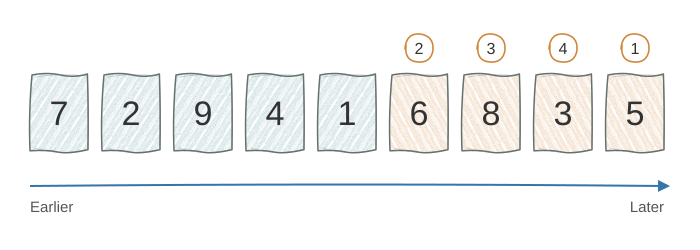

In [3]:
# @title Recall after viewing nine number cards in sequence
display(SVG('<svg xmlns="http://www.w3.org/2000/svg" width="800" style="font-family: Arial, sans-serif; max-width: 100%; height: auto" viewBox="0 0 700 250" role="img" aria-labelledby="tcm-cards-title tcm-cards-desc"><title id="tcm-cards-title">Recall after viewing nine number cards in sequence</title><desc id="tcm-cards-desc">The cards appear in the order 7, 2, 9, 4, 1, 6, 8, 3, 5. Recall proceeds in the order 5, 6, 8, 3.</desc><defs>\n<marker id="tcm-cards-arrow" viewBox="0 0 10 10" refX="5" refY="5" markerWidth="6" markerHeight="6" orient="auto-start-reverse"><path d="M0 0L10 5L0 10Z" fill="#3675a8"/></marker>\n<filter id="tcm-cards-grain" x="-5%" y="-5%" width="110%" height="110%">\n<feTurbulence type="fractalNoise" baseFrequency=".65" numOctaves="3" seed="12" result="grain"/>\n<feColorMatrix in="grain" type="luminanceToAlpha" result="texture"/>\n<feComposite in="SourceGraphic" in2="texture" operator="in"/>\n</filter>\n<pattern id="tcm-cards-hatch" width="19" height="19" patternUnits="userSpaceOnUse" patternTransform="rotate(32)">\n<path d="M2 -3 Q0 6 2 13 L1 23 M7 -3 Q9 8 7 23 M13 -3 Q11 10 14 23 M18 -3 L17 23" fill="none" stroke="#74a4b5" stroke-width="3.3" stroke-linecap="round" opacity=".43"/>\n<path d="M4 -3 L5 23 M11 -3 L10 23" stroke="#aec9b7" stroke-width="1.5" opacity=".5"/>\n</pattern>\n<pattern id="tcm-cards-hatch-warm" width="19" height="19" patternUnits="userSpaceOnUse" patternTransform="rotate(-28)">\n<path d="M2 -3 Q0 6 2 13 L1 23 M7 -3 Q9 8 7 23 M13 -3 Q11 10 14 23 M18 -3 L17 23" fill="none" stroke="#d9a066" stroke-width="3.3" stroke-linecap="round" opacity=".45"/>\n<path d="M4 -3 L5 23 M11 -3 L10 23" stroke="#ecc9a0" stroke-width="1.5" opacity=".55"/>\n</pattern>\n</defs><g><path d="M32 75 Q47.1 72 60.6 75 T87.4 74 Q88.6 105.2 88 149.7 Q67.7 154.3 57.7 152 T30 150.8 Q28.5 113 32 75 Z" fill="#fff"/><path d="M32 75 Q47.1 72 60.6 75 T87.4 74 Q88.6 105.2 88 149.7 Q67.7 154.3 57.7 152 T30 150.8 Q28.5 113 32 75 Z" fill="url(#tcm-cards-hatch)" filter="url(#tcm-cards-grain)"/><path d="M32 75 Q47.1 72 60.6 75 T87.4 74 Q88.6 105.2 88 149.7 Q67.7 154.3 57.7 152 T30 150.8 Q28.5 113 32 75 Z" fill="none" stroke="#65716d" stroke-width="1.5" stroke-linecap="round" stroke-linejoin="round"/><path d="M36 77 Q60 73 86.8 76 M87.4 81 Q88.6 120.8 87.4 147.3 M85.7 149.7 Q58.8 155.9 35 148.1" fill="none" stroke="#65716d" stroke-width=".7" opacity=".38" stroke-linecap="round"/></g><text x="59.0" y="125.0" text-anchor="middle" font-size="34" fill="#323232">7</text><g><path d="M104 75 Q119.1 72 132.6 75 T159.4 74 Q160.6 105.2 160 149.7 Q139.7 154.3 129.7 152 T102 150.8 Q100.5 113 104 75 Z" fill="#fff"/><path d="M104 75 Q119.1 72 132.6 75 T159.4 74 Q160.6 105.2 160 149.7 Q139.7 154.3 129.7 152 T102 150.8 Q100.5 113 104 75 Z" fill="url(#tcm-cards-hatch)" filter="url(#tcm-cards-grain)"/><path d="M104 75 Q119.1 72 132.6 75 T159.4 74 Q160.6 105.2 160 149.7 Q139.7 154.3 129.7 152 T102 150.8 Q100.5 113 104 75 Z" fill="none" stroke="#65716d" stroke-width="1.5" stroke-linecap="round" stroke-linejoin="round"/><path d="M108 77 Q132 73 158.8 76 M159.4 81 Q160.6 120.8 159.4 147.3 M157.7 149.7 Q130.8 155.9 107 148.1" fill="none" stroke="#65716d" stroke-width=".7" opacity=".38" stroke-linecap="round"/></g><text x="131.0" y="125.0" text-anchor="middle" font-size="34" fill="#323232">2</text><g><path d="M176 75 Q191.1 72 204.6 75 T231.4 74 Q232.6 105.2 232 149.7 Q211.7 154.3 201.7 152 T174 150.8 Q172.5 113 176 75 Z" fill="#fff"/><path d="M176 75 Q191.1 72 204.6 75 T231.4 74 Q232.6 105.2 232 149.7 Q211.7 154.3 201.7 152 T174 150.8 Q172.5 113 176 75 Z" fill="url(#tcm-cards-hatch)" filter="url(#tcm-cards-grain)"/><path d="M176 75 Q191.1 72 204.6 75 T231.4 74 Q232.6 105.2 232 149.7 Q211.7 154.3 201.7 152 T174 150.8 Q172.5 113 176 75 Z" fill="none" stroke="#65716d" stroke-width="1.5" stroke-linecap="round" stroke-linejoin="round"/><path d="M180 77 Q204 73 230.8 76 M231.4 81 Q232.6 120.8 231.4 147.3 M229.7 149.7 Q202.8 155.9 179 148.1" fill="none" stroke="#65716d" stroke-width=".7" opacity=".38" stroke-linecap="round"/></g><text x="203.0" y="125.0" text-anchor="middle" font-size="34" fill="#323232">9</text><g><path d="M248 75 Q263.1 72 276.6 75 T303.4 74 Q304.6 105.2 304 149.7 Q283.7 154.3 273.7 152 T246 150.8 Q244.5 113 248 75 Z" fill="#fff"/><path d="M248 75 Q263.1 72 276.6 75 T303.4 74 Q304.6 105.2 304 149.7 Q283.7 154.3 273.7 152 T246 150.8 Q244.5 113 248 75 Z" fill="url(#tcm-cards-hatch)" filter="url(#tcm-cards-grain)"/><path d="M248 75 Q263.1 72 276.6 75 T303.4 74 Q304.6 105.2 304 149.7 Q283.7 154.3 273.7 152 T246 150.8 Q244.5 113 248 75 Z" fill="none" stroke="#65716d" stroke-width="1.5" stroke-linecap="round" stroke-linejoin="round"/><path d="M252 77 Q276 73 302.8 76 M303.4 81 Q304.6 120.8 303.4 147.3 M301.7 149.7 Q274.8 155.9 251 148.1" fill="none" stroke="#65716d" stroke-width=".7" opacity=".38" stroke-linecap="round"/></g><text x="275.0" y="125.0" text-anchor="middle" font-size="34" fill="#323232">4</text><g><path d="M320 75 Q335.1 72 348.6 75 T375.4 74 Q376.6 105.2 376 149.7 Q355.7 154.3 345.7 152 T318 150.8 Q316.5 113 320 75 Z" fill="#fff"/><path d="M320 75 Q335.1 72 348.6 75 T375.4 74 Q376.6 105.2 376 149.7 Q355.7 154.3 345.7 152 T318 150.8 Q316.5 113 320 75 Z" fill="url(#tcm-cards-hatch)" filter="url(#tcm-cards-grain)"/><path d="M320 75 Q335.1 72 348.6 75 T375.4 74 Q376.6 105.2 376 149.7 Q355.7 154.3 345.7 152 T318 150.8 Q316.5 113 320 75 Z" fill="none" stroke="#65716d" stroke-width="1.5" stroke-linecap="round" stroke-linejoin="round"/><path d="M324 77 Q348 73 374.8 76 M375.4 81 Q376.6 120.8 375.4 147.3 M373.7 149.7 Q346.8 155.9 323 148.1" fill="none" stroke="#65716d" stroke-width=".7" opacity=".38" stroke-linecap="round"/></g><text x="347.0" y="125.0" text-anchor="middle" font-size="34" fill="#323232">1</text><g><path d="M392 75 Q407.1 72 420.6 75 T447.4 74 Q448.6 105.2 448 149.7 Q427.7 154.3 417.7 152 T390 150.8 Q388.5 113 392 75 Z" fill="#fff"/><path d="M392 75 Q407.1 72 420.6 75 T447.4 74 Q448.6 105.2 448 149.7 Q427.7 154.3 417.7 152 T390 150.8 Q388.5 113 392 75 Z" fill="url(#tcm-cards-hatch-warm)" filter="url(#tcm-cards-grain)"/><path d="M392 75 Q407.1 72 420.6 75 T447.4 74 Q448.6 105.2 448 149.7 Q427.7 154.3 417.7 152 T390 150.8 Q388.5 113 392 75 Z" fill="none" stroke="#65716d" stroke-width="1.5" stroke-linecap="round" stroke-linejoin="round"/><path d="M396 77 Q420 73 446.8 76 M447.4 81 Q448.6 120.8 447.4 147.3 M445.7 149.7 Q418.8 155.9 395 148.1" fill="none" stroke="#65716d" stroke-width=".7" opacity=".38" stroke-linecap="round"/></g><text x="419.0" y="125.0" text-anchor="middle" font-size="34" fill="#323232">6</text><path d="M405.0 49 Q406.0 33 420.0 34 Q434.0 36 433.0 50 Q431.0 63 418.0 62 Q404.0 61 406.0 45" fill="none" stroke="#d18538" stroke-width="1.6" stroke-linecap="round"/><text x="419.0" y="54" text-anchor="middle" font-size="16" fill="#323232">2</text><g><path d="M464 75 Q479.1 72 492.6 75 T519.4 74 Q520.6 105.2 520 149.7 Q499.7 154.3 489.7 152 T462 150.8 Q460.5 113 464 75 Z" fill="#fff"/><path d="M464 75 Q479.1 72 492.6 75 T519.4 74 Q520.6 105.2 520 149.7 Q499.7 154.3 489.7 152 T462 150.8 Q460.5 113 464 75 Z" fill="url(#tcm-cards-hatch-warm)" filter="url(#tcm-cards-grain)"/><path d="M464 75 Q479.1 72 492.6 75 T519.4 74 Q520.6 105.2 520 149.7 Q499.7 154.3 489.7 152 T462 150.8 Q460.5 113 464 75 Z" fill="none" stroke="#65716d" stroke-width="1.5" stroke-linecap="round" stroke-linejoin="round"/><path d="M468 77 Q492 73 518.8 76 M519.4 81 Q520.6 120.8 519.4 147.3 M517.7 149.7 Q490.8 155.9 467 148.1" fill="none" stroke="#65716d" stroke-width=".7" opacity=".38" stroke-linecap="round"/></g><text x="491.0" y="125.0" text-anchor="middle" font-size="34" fill="#323232">8</text><path d="M477.0 49 Q478.0 33 492.0 34 Q506.0 36 505.0 50 Q503.0 63 490.0 62 Q476.0 61 478.0 45" fill="none" stroke="#d18538" stroke-width="1.6" stroke-linecap="round"/><text x="491.0" y="54" text-anchor="middle" font-size="16" fill="#323232">3</text><g><path d="M536 75 Q551.1 72 564.6 75 T591.4 74 Q592.6 105.2 592 149.7 Q571.7 154.3 561.7 152 T534 150.8 Q532.5 113 536 75 Z" fill="#fff"/><path d="M536 75 Q551.1 72 564.6 75 T591.4 74 Q592.6 105.2 592 149.7 Q571.7 154.3 561.7 152 T534 150.8 Q532.5 113 536 75 Z" fill="url(#tcm-cards-hatch-warm)" filter="url(#tcm-cards-grain)"/><path d="M536 75 Q551.1 72 564.6 75 T591.4 74 Q592.6 105.2 592 149.7 Q571.7 154.3 561.7 152 T534 150.8 Q532.5 113 536 75 Z" fill="none" stroke="#65716d" stroke-width="1.5" stroke-linecap="round" stroke-linejoin="round"/><path d="M540 77 Q564 73 590.8 76 M591.4 81 Q592.6 120.8 591.4 147.3 M589.7 149.7 Q562.8 155.9 539 148.1" fill="none" stroke="#65716d" stroke-width=".7" opacity=".38" stroke-linecap="round"/></g><text x="563.0" y="125.0" text-anchor="middle" font-size="34" fill="#323232">3</text><path d="M549.0 49 Q550.0 33 564.0 34 Q578.0 36 577.0 50 Q575.0 63 562.0 62 Q548.0 61 550.0 45" fill="none" stroke="#d18538" stroke-width="1.6" stroke-linecap="round"/><text x="563.0" y="54" text-anchor="middle" font-size="16" fill="#323232">4</text><g><path d="M608 75 Q623.1 72 636.6 75 T663.4 74 Q664.6 105.2 664 149.7 Q643.7 154.3 633.7 152 T606 150.8 Q604.5 113 608 75 Z" fill="#fff"/><path d="M608 75 Q623.1 72 636.6 75 T663.4 74 Q664.6 105.2 664 149.7 Q643.7 154.3 633.7 152 T606 150.8 Q604.5 113 608 75 Z" fill="url(#tcm-cards-hatch-warm)" filter="url(#tcm-cards-grain)"/><path d="M608 75 Q623.1 72 636.6 75 T663.4 74 Q664.6 105.2 664 149.7 Q643.7 154.3 633.7 152 T606 150.8 Q604.5 113 608 75 Z" fill="none" stroke="#65716d" stroke-width="1.5" stroke-linecap="round" stroke-linejoin="round"/><path d="M612 77 Q636 73 662.8 76 M663.4 81 Q664.6 120.8 663.4 147.3 M661.7 149.7 Q634.8 155.9 611 148.1" fill="none" stroke="#65716d" stroke-width=".7" opacity=".38" stroke-linecap="round"/></g><text x="635.0" y="125.0" text-anchor="middle" font-size="34" fill="#323232">5</text><path d="M621.0 49 Q622.0 33 636.0 34 Q650.0 36 649.0 50 Q647.0 63 634.0 62 Q620.0 61 622.0 45" fill="none" stroke="#d18538" stroke-width="1.6" stroke-linecap="round"/><text x="635.0" y="54" text-anchor="middle" font-size="16" fill="#323232">1</text><path d="M30 186 Q347.0 183 664 186" stroke="#3675a8" stroke-width="2" fill="none" marker-end="url(#tcm-cards-arrow)"/><text x="30" y="212" font-size="15" fill="#555">Earlier</text><text x="664" y="212" font-size="15" fill="#555" text-anchor="end">Later</text></svg>'))

<figcaption>The numbers above the cards mark recall order: starting at the end, then moving between nearby cards, usually forward.</figcaption>

<p>Howard and Kahana (2002) proposed that timing is represented by a slowly changing state of <em>temporal context</em>. Each word becomes associated with the context in which it appears. At test, the current context serves as a retrieval cue and most closely resembles the contexts of the last few words. Recalling a word brings back part of its study context, making nearby words easier to recall.</p>

<p>To explain both effects, context must capture two temporal relationships. Recency depends on how much time has passed since each word appeared. Contiguity requires returning to the context of a recalled word and recovering how close other words were to it.</p>

<p>Earlier models treated context as a set of randomly changing elements. They could describe recency, but lacked a way to recover an earlier context and explain contiguity. In the temporal context model (TCM), the content of experience determines how context changes. Each word retrieves an associated context and blends it into the current state. Recalling the word retrieves that context again. A forward bias follows because the context introduced by a word persists only in subsequent states. With this mechanism and a small set of parameters, the authors sought to explain recency and contiguity over both short and long intervals.</p>

## Temporal context model

<p>The temporal context model describes learning and recall through associations between words and context. During study, each word becomes linked to the context in which it appears. During recall, the current context activates words, and a recalled word changes the context in turn. We illustrate this process with a list of 12 words.</p>

### 1. Items and temporal context

<p>The model has an item layer F and a context layer T. The item layer represents the word currently being presented or recalled, with one unit per word: when “apple” is presented, its unit is active and all others are inactive. Activity in the context layer is represented by a vector <strong>t</strong>, which retains the influence of past experience and changes as new items arrive.</p>

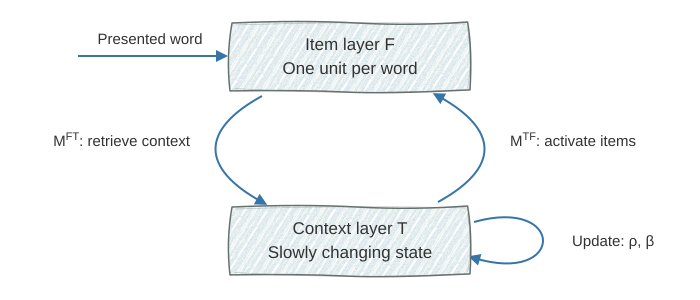

In [4]:
# @title Two directions of association connect the item and context layers
display(SVG('<svg xmlns="http://www.w3.org/2000/svg" width="800" style="font-family: Arial, sans-serif; max-width: 100%; height: auto" viewBox="0 0 700 300" role="img" aria-labelledby="tcm-net-title tcm-net-desc"><title id="tcm-net-title">Two directions of association connect the item and context layers</title><desc id="tcm-net-desc">A word activates the item layer, which retrieves context through M FT. Retrieved context enters the current state, which activates items through M TF.</desc><defs>\n<marker id="tcm-net-arrow" viewBox="0 0 10 10" refX="5" refY="5" markerWidth="6" markerHeight="6" orient="auto-start-reverse"><path d="M0 0L10 5L0 10Z" fill="#3675a8"/></marker>\n<filter id="tcm-net-grain" x="-5%" y="-5%" width="110%" height="110%">\n<feTurbulence type="fractalNoise" baseFrequency=".65" numOctaves="3" seed="12" result="grain"/>\n<feColorMatrix in="grain" type="luminanceToAlpha" result="texture"/>\n<feComposite in="SourceGraphic" in2="texture" operator="in"/>\n</filter>\n<pattern id="tcm-net-hatch" width="19" height="19" patternUnits="userSpaceOnUse" patternTransform="rotate(32)">\n<path d="M2 -3 Q0 6 2 13 L1 23 M7 -3 Q9 8 7 23 M13 -3 Q11 10 14 23 M18 -3 L17 23" fill="none" stroke="#74a4b5" stroke-width="3.3" stroke-linecap="round" opacity=".43"/>\n<path d="M4 -3 L5 23 M11 -3 L10 23" stroke="#aec9b7" stroke-width="1.5" opacity=".5"/>\n</pattern>\n<pattern id="tcm-net-hatch-warm" width="19" height="19" patternUnits="userSpaceOnUse" patternTransform="rotate(-28)">\n<path d="M2 -3 Q0 6 2 13 L1 23 M7 -3 Q9 8 7 23 M13 -3 Q11 10 14 23 M18 -3 L17 23" fill="none" stroke="#d9a066" stroke-width="3.3" stroke-linecap="round" opacity=".45"/>\n<path d="M4 -3 L5 23 M11 -3 L10 23" stroke="#ecc9a0" stroke-width="1.5" opacity=".55"/>\n</pattern>\n</defs><g stroke="#3675a8" stroke-width="2" fill="none" marker-end="url(#tcm-net-arrow)"><path d="M78 56H222"/><path d="M262 96C200 130 200 168 262 202"/><path d="M438 202C500 168 500 130 438 96"/><path d="M474 222C566 196 566 286 474 258"/></g><g><path d="M232 23 Q300.6 20 356.7 23 T467.6 22 Q472.4 50 470 89.9 Q386 94.1 344.5 92 T230 90.9 Q226 57 232 23 Z" fill="#fff"/><path d="M232 23 Q300.6 20 356.7 23 T467.6 22 Q472.4 50 470 89.9 Q386 94.1 344.5 92 T230 90.9 Q226 57 232 23 Z" fill="url(#tcm-net-hatch)" filter="url(#tcm-net-grain)"/><path d="M232 23 Q300.6 20 356.7 23 T467.6 22 Q472.4 50 470 89.9 Q386 94.1 344.5 92 T230 90.9 Q226 57 232 23 Z" fill="none" stroke="#65716d" stroke-width="1.5" stroke-linecap="round" stroke-linejoin="round"/><path d="M236 25 Q354.3 21 465.2 24 M467.6 29 Q472.4 64 467.6 87.8 M460.4 89.9 Q349.3 95.5 235 88.5" fill="none" stroke="#65716d" stroke-width=".7" opacity=".38" stroke-linecap="round"/></g><g><path d="M232 207 Q300.6 204 356.7 207 T467.6 206 Q472.4 234 470 273.9 Q386 278.1 344.5 276 T230 274.9 Q226 241 232 207 Z" fill="#fff"/><path d="M232 207 Q300.6 204 356.7 207 T467.6 206 Q472.4 234 470 273.9 Q386 278.1 344.5 276 T230 274.9 Q226 241 232 207 Z" fill="url(#tcm-net-hatch)" filter="url(#tcm-net-grain)"/><path d="M232 207 Q300.6 204 356.7 207 T467.6 206 Q472.4 234 470 273.9 Q386 278.1 344.5 276 T230 274.9 Q226 241 232 207 Z" fill="none" stroke="#65716d" stroke-width="1.5" stroke-linecap="round" stroke-linejoin="round"/><path d="M236 209 Q354.3 205 465.2 208 M467.6 213 Q472.4 248 467.6 271.8 M460.4 273.9 Q349.3 279.5 235 272.5" fill="none" stroke="#65716d" stroke-width=".7" opacity=".38" stroke-linecap="round"/></g><g text-anchor="middle" fill="#323232" font-size="17"><text x="350" y="50">Item layer F</text><text x="350" y="74">One unit per word</text><text x="350" y="234">Context layer T</text><text x="350" y="258">Slowly changing state</text></g><g fill="#323232" font-size="15"><text x="150" y="44" text-anchor="middle">Presented word</text><text x="190" y="146" text-anchor="end">M<tspan font-size="11" dy="-6">FT</tspan><tspan dy="6">: retrieve context</tspan></text><text x="510" y="146">M<tspan font-size="11" dy="-6">TF</tspan><tspan dy="6">: activate items</tspan></text><text x="572" y="246">Update: ρ, β</text></g></svg>'))

<figcaption>M<sup>FT</sup> retrieves context from an item; M<sup>TF</sup> stores item–context associations and activates items during recall.</figcaption>

<p>The words already have a history before the experiment. The model calls the context retrieved through these existing associations <em>pre-experimental context</em>. For a randomly assembled word list, different words are assumed to have unrelated pre-experimental contexts, represented here by orthogonal vectors.</p>

### 2. Learning and context updating

<p>When word <em>i</em> first appears, M<sup>FT</sup> retrieves its pre-experimental context t<sup>IN</sup><sub>i</sub>. This input combines with the previous context to form the new state:</p>

<div class="equation">t<sub>i</sub> = ρt<sub>i−1</sub> + βt<sup>IN</sup><sub>i</sub></div>

<p>β controls the influence of new input on context. As distinct words are studied, a larger β produces faster context change and a faster decline in the influence of earlier inputs. ρ keeps the context vector at unit length; it is not an additional free parameter. When the input is orthogonal to the previous context, ρ = √(1 − β²).</p>

<details class="code-fold"><summary>General expression for ρ</summary><div class="equation">ρ<sub>i</sub> = √(1 + β²[(t<sub>i−1</sub>·t<sup>IN</sup><sub>i</sub>)² − 1]) − β(t<sub>i−1</sub>·t<sup>IN</sup><sub>i</sub>)</div><p>When the dot product is zero, the expression reduces to √(1 − β²). A repeated word can retrieve components that overlap with the current context, so ρ must then be calculated from their dot product.</p></details>

#### Context during study

<p>Play or step through the list to follow the context components above and their similarity to each word’s study context below.</p>

FloatSlider(value=0.4, continuous_update=False, description='β', max=0.9, min=0.1, step=0.01)

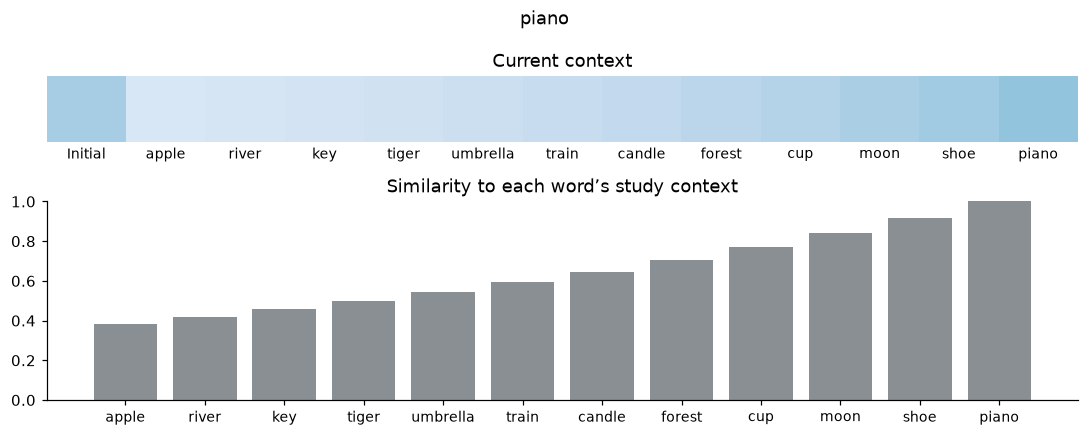

In [5]:
# @title Context during study
study_step = widgets.IntSlider(value=12, min=0, max=12, description='Word', continuous_update=False)
study_play = widgets.Play(value=12, min=0, max=12, interval=900)
study_link = widgets.jslink((study_play, 'value'), (study_step, 'value'))
study_beta = widgets.FloatSlider(value=.40, min=.1, max=.9, step=.01, description='β', continuous_update=False)
study_view = FigureView()

def draw_study(change=None):
    model = TemporalContextModel(12, params=Parameters(beta=study_beta.value))
    history = [model.present(i)['context'] for i in range(study_step.value)]
    similarity = np.zeros(12)
    if history:
        similarity[:len(history)] = (torch.stack(history) @ model.context).numpy()
    fig, ax = plt.subplots(2, 1, figsize=(10, 4), gridspec_kw={'height_ratios': [1, 3]})
    context_strip(ax[0], model.context)
    word_bars(ax[1], similarity, 'Similarity to each word’s study context', GREY)
    fig.suptitle(WORDS[study_step.value - 1] if history else 'Ready')
    study_view.show(fig)

study_step.observe(draw_study, names='value')
study_beta.observe(draw_study, names='value')
display(widgets.HBox([study_play, study_step]), study_beta)
draw_study()

<p>After updating context, the model stores the association between the current word and this context in M<sup>TF</sup>. Because context changes gradually, neighboring words have similar study contexts. Words farther apart in the list have less similar contexts.</p>

### 3. First recall

<p>At the start of recall, the current context activates the words through M<sup>TF</sup>. When each word has been studied once, its activation is the dot product of its study context and the test context:</p>

<div class="equation">a<sub>i</sub> = t<sub>i</sub> · t<sub>test</sub></div>

<p>The study contexts of the last few words resemble the test context most closely, giving those words higher activation. The model converts activations into recall probabilities, with the denominator summing over all words in the list:</p>

<div class="equation">P(i) = exp(2a<sub>i</sub>/τ) / Σ<sub>j</sub> exp(2a<sub>j</sub>/τ)</div>

<p>τ controls how strongly recall probabilities depend on differences in activation. A small τ concentrates probability on highly activated words; a larger τ makes the probabilities more similar.</p>

#### From activation to probability

<p>Gray bars show activation; blue bars show the probability of first recall.</p>

FloatSlider(value=0.25, continuous_update=False, description='τ', max=1.0, min=0.05, step=0.01)

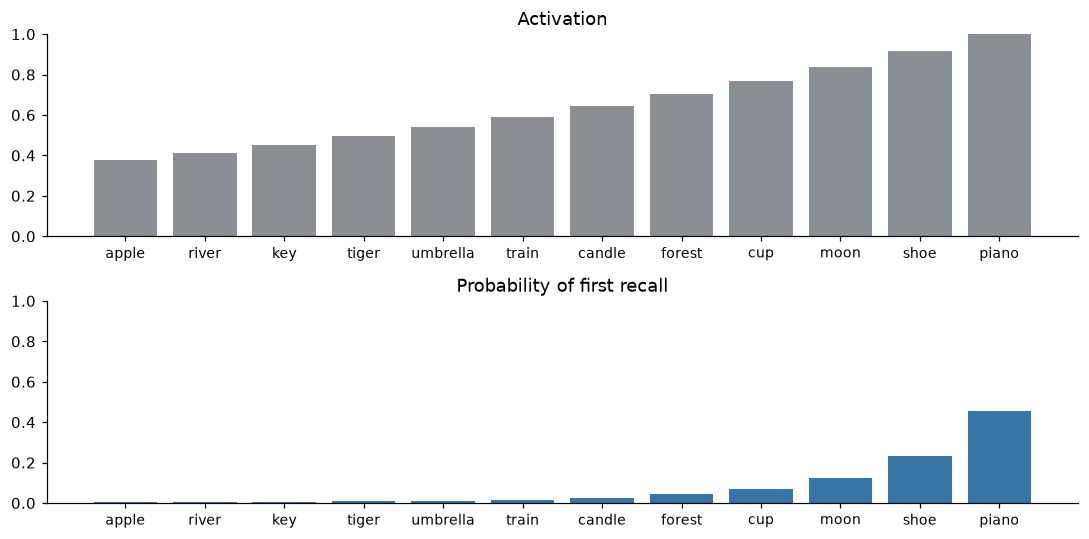

In [6]:
# @title From activation to probability
choice_tau = widgets.FloatSlider(value=.25, min=.05, max=1, step=.01, description='τ', continuous_update=False)
choice_view = FigureView()

def draw_choice(change=None):
    model, _ = study_list('immediate', Parameters(tau=choice_tau.value))
    fig, ax = plt.subplots(2, 1, figsize=(10, 5))
    word_bars(ax[0], model.activations().numpy(), 'Activation', GREY)
    word_bars(ax[1], model.probabilities().numpy(), 'Probability of first recall')
    choice_view.show(fig)

choice_tau.observe(draw_choice, names='value')
display(choice_tau)
draw_choice()

<p>A word’s recall probability depends on how its activation compares with that of other words. Distraction before test changes context, usually reducing these differences and weakening the advantage of recent words. Recency can persist as long as the final items retain higher activation.</p>

### 4. Recall and context reinstatement

<p>A recalled word retrieves context through M<sup>FT</sup> again. Learning has changed its associations, so the retrieved context now contains both its pre-experimental context and the context in which it appeared in this list. γ is the ratio of the former weight to the latter; the paper uses γ = 1, giving both components equal weight.</p>

<p>These components affect subsequent recall differently. The study context resembles the contexts of both preceding and following neighbors, supporting recall in both directions. The pre-experimental context entered the context state when the word appeared and persisted in later states, but was absent from earlier ones. This component favors later items and produces the forward bias.</p>

#### How recall changes probabilities

<p>Select a word or click “Sample recall” to see how recall changes context.</p>

GridBox(children=(Button(description='apple', layout=Layout(width='80px'), style=ButtonStyle()), Button(descri…

HTML(value='')

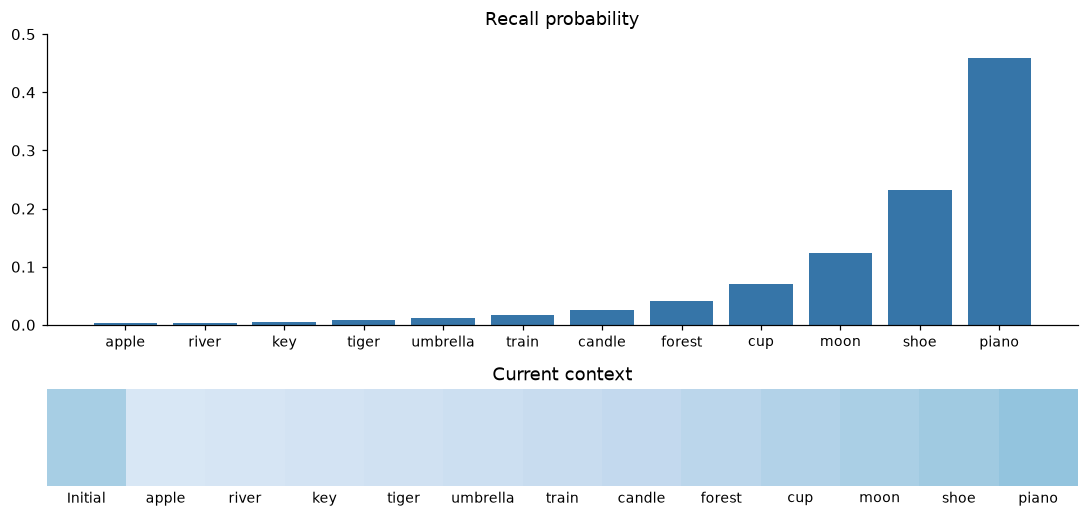

In [7]:
# @title How recall changes probabilities
recall_condition = widgets.Dropdown(options=[(TITLES[c], c) for c in ['immediate', 'delayed']], description='Condition')
recall_gamma = widgets.FloatSlider(value=1, min=0, max=3, step=.1, description='γ', continuous_update=False)
recall_sample = widgets.Button(description='Sample recall')
recall_reset = widgets.Button(description='Start again')
recall_words = [widgets.Button(description=word, layout=widgets.Layout(width='80px')) for word in WORDS]
recall_sequence = widgets.HTML()
recall_view = FigureView()
recall_state = {}

def draw_recall():
    model, recalled = recall_state['model'], recall_state['recalled']
    done = len(recalled) == 12
    probability = np.zeros(12) if done else model.probabilities(recalled).numpy()
    fig, ax = plt.subplots(2, 1, figsize=(10, 4.8), gridspec_kw={'height_ratios': [3, 1]})
    word_bars(ax[0], probability, 'Recall probability', upper=max(.5, float(probability.max())))
    context_strip(ax[1], model.context)
    for i, button in enumerate(recall_words):
        button.disabled = i in recalled
    recall_sample.disabled = done
    sequence = [WORDS[k] if j == 0 else f'{WORDS[k]} ({k - recalled[j-1]:+d})'
                for j, k in enumerate(recalled)]
    recall_sequence.value = 'Recall order: ' + ' → '.join(sequence) if recalled else 'No words recalled yet.'
    recall_view.show(fig)

def reset_recall(change=None):
    params = Parameters(gamma=recall_gamma.value)
    recall_state['model'], _ = study_list(recall_condition.value, params)
    recall_state['recalled'] = []
    draw_recall()

def choose_recall(item):
    if item in recall_state['recalled'] or len(recall_state['recalled']) == 12:
        return
    recall_state['model'].present(item)
    recall_state['recalled'].append(item)
    draw_recall()

def sample_recall(button=None):
    if len(recall_state['recalled']) < 12:
        probability = recall_state['model'].probabilities(recall_state['recalled'])
        choose_recall(int(torch.multinomial(probability, 1)))

for i, button in enumerate(recall_words):
    button.on_click(lambda button, i=i: choose_recall(i))
recall_sample.on_click(sample_recall)
recall_reset.on_click(reset_recall)
recall_condition.observe(reset_recall, names='value')
recall_gamma.observe(reset_recall, names='value')
display(widgets.HBox([recall_condition, recall_gamma]),
        widgets.GridBox(recall_words, layout=widgets.Layout(grid_template_columns='repeat(6, 80px)')),
        recall_sequence, widgets.HBox([recall_sample, recall_reset]))
reset_recall()

### 5. Delay and continuous distraction

<p>Howard and Kahana (1999) compared free recall under three timing conditions. <em>Immediate recall</em> begins as soon as the list ends. <em>Delayed recall</em> follows 16 seconds of arithmetic after the list. In <em>continuous-distractor recall</em>, arithmetic also follows each word, separating the words in time.</p>

<p>Arithmetic also changes context. The model represents a distractor interval by its effective length <em>d</em>: the number of unrelated items that would produce the same context change. The authors reasoned that similar arithmetic problems may produce less change than new words over the same duration. Thus, <em>d</em> is fitted to the data rather than measured directly in seconds.</p>

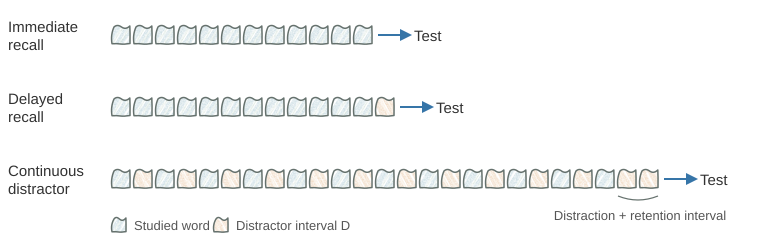

In [8]:
# @title Study sequences in the three experimental conditions
display(SVG('<svg xmlns="http://www.w3.org/2000/svg" width="800" style="font-family: Arial, sans-serif; max-width: 100%; height: auto" viewBox="0 0 760 250" role="img" aria-labelledby="tcm-list-title tcm-list-desc"><title id="tcm-list-title">Study sequences in the three experimental conditions</title><desc id="tcm-list-desc">Blue blocks represent studied words and orange blocks represent distractor intervals. In continuous-distractor recall, each word is followed by distraction, with a further retention interval after the final word.</desc><defs>\n<marker id="tcm-list-arrow" viewBox="0 0 10 10" refX="5" refY="5" markerWidth="6" markerHeight="6" orient="auto-start-reverse"><path d="M0 0L10 5L0 10Z" fill="#3675a8"/></marker>\n<filter id="tcm-list-grain" x="-5%" y="-5%" width="110%" height="110%">\n<feTurbulence type="fractalNoise" baseFrequency=".65" numOctaves="3" seed="12" result="grain"/>\n<feColorMatrix in="grain" type="luminanceToAlpha" result="texture"/>\n<feComposite in="SourceGraphic" in2="texture" operator="in"/>\n</filter>\n<pattern id="tcm-list-hatch" width="19" height="19" patternUnits="userSpaceOnUse" patternTransform="rotate(32)">\n<path d="M2 -3 Q0 6 2 13 L1 23 M7 -3 Q9 8 7 23 M13 -3 Q11 10 14 23 M18 -3 L17 23" fill="none" stroke="#74a4b5" stroke-width="3.3" stroke-linecap="round" opacity=".43"/>\n<path d="M4 -3 L5 23 M11 -3 L10 23" stroke="#aec9b7" stroke-width="1.5" opacity=".5"/>\n</pattern>\n<pattern id="tcm-list-hatch-warm" width="19" height="19" patternUnits="userSpaceOnUse" patternTransform="rotate(-28)">\n<path d="M2 -3 Q0 6 2 13 L1 23 M7 -3 Q9 8 7 23 M13 -3 Q11 10 14 23 M18 -3 L17 23" fill="none" stroke="#d9a066" stroke-width="3.3" stroke-linecap="round" opacity=".45"/>\n<path d="M4 -3 L5 23 M11 -3 L10 23" stroke="#ecc9a0" stroke-width="1.5" opacity=".55"/>\n</pattern>\n</defs><text x="8" y="32" font-size="15" fill="#323232"><tspan x="8">Immediate</tspan><tspan x="8" dy="18">recall</tspan></text><g><path d="M114 27 Q117.3 24 121.5 27 T129.8 26 Q130.2 33.2 130 43.5 Q123.7 44.5 120.6 44 T112 43.7 Q110.5 35 114 27 Z" fill="#fff"/><path d="M114 27 Q117.3 24 121.5 27 T129.8 26 Q130.2 33.2 130 43.5 Q123.7 44.5 120.6 44 T112 43.7 Q110.5 35 114 27 Z" fill="url(#tcm-list-hatch)" filter="url(#tcm-list-grain)"/><path d="M114 27 Q117.3 24 121.5 27 T129.8 26 Q130.2 33.2 130 43.5 Q123.7 44.5 120.6 44 T112 43.7 Q110.5 35 114 27 Z" fill="none" stroke="#65716d" stroke-width="1.5" stroke-linecap="round" stroke-linejoin="round"/></g><g><path d="M136 27 Q139.3 24 143.5 27 T151.8 26 Q152.2 33.2 152 43.5 Q145.7 44.5 142.6 44 T134 43.7 Q132.5 35 136 27 Z" fill="#fff"/><path d="M136 27 Q139.3 24 143.5 27 T151.8 26 Q152.2 33.2 152 43.5 Q145.7 44.5 142.6 44 T134 43.7 Q132.5 35 136 27 Z" fill="url(#tcm-list-hatch)" filter="url(#tcm-list-grain)"/><path d="M136 27 Q139.3 24 143.5 27 T151.8 26 Q152.2 33.2 152 43.5 Q145.7 44.5 142.6 44 T134 43.7 Q132.5 35 136 27 Z" fill="none" stroke="#65716d" stroke-width="1.5" stroke-linecap="round" stroke-linejoin="round"/></g><g><path d="M158 27 Q161.3 24 165.5 27 T173.8 26 Q174.2 33.2 174 43.5 Q167.7 44.5 164.6 44 T156 43.7 Q154.5 35 158 27 Z" fill="#fff"/><path d="M158 27 Q161.3 24 165.5 27 T173.8 26 Q174.2 33.2 174 43.5 Q167.7 44.5 164.6 44 T156 43.7 Q154.5 35 158 27 Z" fill="url(#tcm-list-hatch)" filter="url(#tcm-list-grain)"/><path d="M158 27 Q161.3 24 165.5 27 T173.8 26 Q174.2 33.2 174 43.5 Q167.7 44.5 164.6 44 T156 43.7 Q154.5 35 158 27 Z" fill="none" stroke="#65716d" stroke-width="1.5" stroke-linecap="round" stroke-linejoin="round"/></g><g><path d="M180 27 Q183.3 24 187.5 27 T195.8 26 Q196.2 33.2 196 43.5 Q189.7 44.5 186.6 44 T178 43.7 Q176.5 35 180 27 Z" fill="#fff"/><path d="M180 27 Q183.3 24 187.5 27 T195.8 26 Q196.2 33.2 196 43.5 Q189.7 44.5 186.6 44 T178 43.7 Q176.5 35 180 27 Z" fill="url(#tcm-list-hatch)" filter="url(#tcm-list-grain)"/><path d="M180 27 Q183.3 24 187.5 27 T195.8 26 Q196.2 33.2 196 43.5 Q189.7 44.5 186.6 44 T178 43.7 Q176.5 35 180 27 Z" fill="none" stroke="#65716d" stroke-width="1.5" stroke-linecap="round" stroke-linejoin="round"/></g><g><path d="M202 27 Q205.3 24 209.5 27 T217.8 26 Q218.2 33.2 218 43.5 Q211.7 44.5 208.6 44 T200 43.7 Q198.5 35 202 27 Z" fill="#fff"/><path d="M202 27 Q205.3 24 209.5 27 T217.8 26 Q218.2 33.2 218 43.5 Q211.7 44.5 208.6 44 T200 43.7 Q198.5 35 202 27 Z" fill="url(#tcm-list-hatch)" filter="url(#tcm-list-grain)"/><path d="M202 27 Q205.3 24 209.5 27 T217.8 26 Q218.2 33.2 218 43.5 Q211.7 44.5 208.6 44 T200 43.7 Q198.5 35 202 27 Z" fill="none" stroke="#65716d" stroke-width="1.5" stroke-linecap="round" stroke-linejoin="round"/></g><g><path d="M224 27 Q227.3 24 231.5 27 T239.8 26 Q240.2 33.2 240 43.5 Q233.7 44.5 230.6 44 T222 43.7 Q220.5 35 224 27 Z" fill="#fff"/><path d="M224 27 Q227.3 24 231.5 27 T239.8 26 Q240.2 33.2 240 43.5 Q233.7 44.5 230.6 44 T222 43.7 Q220.5 35 224 27 Z" fill="url(#tcm-list-hatch)" filter="url(#tcm-list-grain)"/><path d="M224 27 Q227.3 24 231.5 27 T239.8 26 Q240.2 33.2 240 43.5 Q233.7 44.5 230.6 44 T222 43.7 Q220.5 35 224 27 Z" fill="none" stroke="#65716d" stroke-width="1.5" stroke-linecap="round" stroke-linejoin="round"/></g><g><path d="M246 27 Q249.3 24 253.5 27 T261.8 26 Q262.2 33.2 262 43.5 Q255.7 44.5 252.6 44 T244 43.7 Q242.5 35 246 27 Z" fill="#fff"/><path d="M246 27 Q249.3 24 253.5 27 T261.8 26 Q262.2 33.2 262 43.5 Q255.7 44.5 252.6 44 T244 43.7 Q242.5 35 246 27 Z" fill="url(#tcm-list-hatch)" filter="url(#tcm-list-grain)"/><path d="M246 27 Q249.3 24 253.5 27 T261.8 26 Q262.2 33.2 262 43.5 Q255.7 44.5 252.6 44 T244 43.7 Q242.5 35 246 27 Z" fill="none" stroke="#65716d" stroke-width="1.5" stroke-linecap="round" stroke-linejoin="round"/></g><g><path d="M268 27 Q271.3 24 275.5 27 T283.8 26 Q284.2 33.2 284 43.5 Q277.7 44.5 274.6 44 T266 43.7 Q264.5 35 268 27 Z" fill="#fff"/><path d="M268 27 Q271.3 24 275.5 27 T283.8 26 Q284.2 33.2 284 43.5 Q277.7 44.5 274.6 44 T266 43.7 Q264.5 35 268 27 Z" fill="url(#tcm-list-hatch)" filter="url(#tcm-list-grain)"/><path d="M268 27 Q271.3 24 275.5 27 T283.8 26 Q284.2 33.2 284 43.5 Q277.7 44.5 274.6 44 T266 43.7 Q264.5 35 268 27 Z" fill="none" stroke="#65716d" stroke-width="1.5" stroke-linecap="round" stroke-linejoin="round"/></g><g><path d="M290 27 Q293.3 24 297.5 27 T305.8 26 Q306.2 33.2 306 43.5 Q299.7 44.5 296.6 44 T288 43.7 Q286.5 35 290 27 Z" fill="#fff"/><path d="M290 27 Q293.3 24 297.5 27 T305.8 26 Q306.2 33.2 306 43.5 Q299.7 44.5 296.6 44 T288 43.7 Q286.5 35 290 27 Z" fill="url(#tcm-list-hatch)" filter="url(#tcm-list-grain)"/><path d="M290 27 Q293.3 24 297.5 27 T305.8 26 Q306.2 33.2 306 43.5 Q299.7 44.5 296.6 44 T288 43.7 Q286.5 35 290 27 Z" fill="none" stroke="#65716d" stroke-width="1.5" stroke-linecap="round" stroke-linejoin="round"/></g><g><path d="M312 27 Q315.3 24 319.5 27 T327.8 26 Q328.2 33.2 328 43.5 Q321.7 44.5 318.6 44 T310 43.7 Q308.5 35 312 27 Z" fill="#fff"/><path d="M312 27 Q315.3 24 319.5 27 T327.8 26 Q328.2 33.2 328 43.5 Q321.7 44.5 318.6 44 T310 43.7 Q308.5 35 312 27 Z" fill="url(#tcm-list-hatch)" filter="url(#tcm-list-grain)"/><path d="M312 27 Q315.3 24 319.5 27 T327.8 26 Q328.2 33.2 328 43.5 Q321.7 44.5 318.6 44 T310 43.7 Q308.5 35 312 27 Z" fill="none" stroke="#65716d" stroke-width="1.5" stroke-linecap="round" stroke-linejoin="round"/></g><g><path d="M334 27 Q337.3 24 341.5 27 T349.8 26 Q350.2 33.2 350 43.5 Q343.7 44.5 340.6 44 T332 43.7 Q330.5 35 334 27 Z" fill="#fff"/><path d="M334 27 Q337.3 24 341.5 27 T349.8 26 Q350.2 33.2 350 43.5 Q343.7 44.5 340.6 44 T332 43.7 Q330.5 35 334 27 Z" fill="url(#tcm-list-hatch)" filter="url(#tcm-list-grain)"/><path d="M334 27 Q337.3 24 341.5 27 T349.8 26 Q350.2 33.2 350 43.5 Q343.7 44.5 340.6 44 T332 43.7 Q330.5 35 334 27 Z" fill="none" stroke="#65716d" stroke-width="1.5" stroke-linecap="round" stroke-linejoin="round"/></g><g><path d="M356 27 Q359.3 24 363.5 27 T371.8 26 Q372.2 33.2 372 43.5 Q365.7 44.5 362.6 44 T354 43.7 Q352.5 35 356 27 Z" fill="#fff"/><path d="M356 27 Q359.3 24 363.5 27 T371.8 26 Q372.2 33.2 372 43.5 Q365.7 44.5 362.6 44 T354 43.7 Q352.5 35 356 27 Z" fill="url(#tcm-list-hatch)" filter="url(#tcm-list-grain)"/><path d="M356 27 Q359.3 24 363.5 27 T371.8 26 Q372.2 33.2 372 43.5 Q365.7 44.5 362.6 44 T354 43.7 Q352.5 35 356 27 Z" fill="none" stroke="#65716d" stroke-width="1.5" stroke-linecap="round" stroke-linejoin="round"/></g><path d="M378 35H406" stroke="#3675a8" stroke-width="2" fill="none" marker-end="url(#tcm-list-arrow)"/><text x="414" y="41" font-size="15" fill="#323232">Test</text><text x="8" y="104" font-size="15" fill="#323232"><tspan x="8">Delayed</tspan><tspan x="8" dy="18">recall</tspan></text><g><path d="M114 99 Q117.3 96 121.5 99 T129.8 98 Q130.2 105.2 130 115.5 Q123.7 116.5 120.6 116 T112 115.7 Q110.5 107 114 99 Z" fill="#fff"/><path d="M114 99 Q117.3 96 121.5 99 T129.8 98 Q130.2 105.2 130 115.5 Q123.7 116.5 120.6 116 T112 115.7 Q110.5 107 114 99 Z" fill="url(#tcm-list-hatch)" filter="url(#tcm-list-grain)"/><path d="M114 99 Q117.3 96 121.5 99 T129.8 98 Q130.2 105.2 130 115.5 Q123.7 116.5 120.6 116 T112 115.7 Q110.5 107 114 99 Z" fill="none" stroke="#65716d" stroke-width="1.5" stroke-linecap="round" stroke-linejoin="round"/></g><g><path d="M136 99 Q139.3 96 143.5 99 T151.8 98 Q152.2 105.2 152 115.5 Q145.7 116.5 142.6 116 T134 115.7 Q132.5 107 136 99 Z" fill="#fff"/><path d="M136 99 Q139.3 96 143.5 99 T151.8 98 Q152.2 105.2 152 115.5 Q145.7 116.5 142.6 116 T134 115.7 Q132.5 107 136 99 Z" fill="url(#tcm-list-hatch)" filter="url(#tcm-list-grain)"/><path d="M136 99 Q139.3 96 143.5 99 T151.8 98 Q152.2 105.2 152 115.5 Q145.7 116.5 142.6 116 T134 115.7 Q132.5 107 136 99 Z" fill="none" stroke="#65716d" stroke-width="1.5" stroke-linecap="round" stroke-linejoin="round"/></g><g><path d="M158 99 Q161.3 96 165.5 99 T173.8 98 Q174.2 105.2 174 115.5 Q167.7 116.5 164.6 116 T156 115.7 Q154.5 107 158 99 Z" fill="#fff"/><path d="M158 99 Q161.3 96 165.5 99 T173.8 98 Q174.2 105.2 174 115.5 Q167.7 116.5 164.6 116 T156 115.7 Q154.5 107 158 99 Z" fill="url(#tcm-list-hatch)" filter="url(#tcm-list-grain)"/><path d="M158 99 Q161.3 96 165.5 99 T173.8 98 Q174.2 105.2 174 115.5 Q167.7 116.5 164.6 116 T156 115.7 Q154.5 107 158 99 Z" fill="none" stroke="#65716d" stroke-width="1.5" stroke-linecap="round" stroke-linejoin="round"/></g><g><path d="M180 99 Q183.3 96 187.5 99 T195.8 98 Q196.2 105.2 196 115.5 Q189.7 116.5 186.6 116 T178 115.7 Q176.5 107 180 99 Z" fill="#fff"/><path d="M180 99 Q183.3 96 187.5 99 T195.8 98 Q196.2 105.2 196 115.5 Q189.7 116.5 186.6 116 T178 115.7 Q176.5 107 180 99 Z" fill="url(#tcm-list-hatch)" filter="url(#tcm-list-grain)"/><path d="M180 99 Q183.3 96 187.5 99 T195.8 98 Q196.2 105.2 196 115.5 Q189.7 116.5 186.6 116 T178 115.7 Q176.5 107 180 99 Z" fill="none" stroke="#65716d" stroke-width="1.5" stroke-linecap="round" stroke-linejoin="round"/></g><g><path d="M202 99 Q205.3 96 209.5 99 T217.8 98 Q218.2 105.2 218 115.5 Q211.7 116.5 208.6 116 T200 115.7 Q198.5 107 202 99 Z" fill="#fff"/><path d="M202 99 Q205.3 96 209.5 99 T217.8 98 Q218.2 105.2 218 115.5 Q211.7 116.5 208.6 116 T200 115.7 Q198.5 107 202 99 Z" fill="url(#tcm-list-hatch)" filter="url(#tcm-list-grain)"/><path d="M202 99 Q205.3 96 209.5 99 T217.8 98 Q218.2 105.2 218 115.5 Q211.7 116.5 208.6 116 T200 115.7 Q198.5 107 202 99 Z" fill="none" stroke="#65716d" stroke-width="1.5" stroke-linecap="round" stroke-linejoin="round"/></g><g><path d="M224 99 Q227.3 96 231.5 99 T239.8 98 Q240.2 105.2 240 115.5 Q233.7 116.5 230.6 116 T222 115.7 Q220.5 107 224 99 Z" fill="#fff"/><path d="M224 99 Q227.3 96 231.5 99 T239.8 98 Q240.2 105.2 240 115.5 Q233.7 116.5 230.6 116 T222 115.7 Q220.5 107 224 99 Z" fill="url(#tcm-list-hatch)" filter="url(#tcm-list-grain)"/><path d="M224 99 Q227.3 96 231.5 99 T239.8 98 Q240.2 105.2 240 115.5 Q233.7 116.5 230.6 116 T222 115.7 Q220.5 107 224 99 Z" fill="none" stroke="#65716d" stroke-width="1.5" stroke-linecap="round" stroke-linejoin="round"/></g><g><path d="M246 99 Q249.3 96 253.5 99 T261.8 98 Q262.2 105.2 262 115.5 Q255.7 116.5 252.6 116 T244 115.7 Q242.5 107 246 99 Z" fill="#fff"/><path d="M246 99 Q249.3 96 253.5 99 T261.8 98 Q262.2 105.2 262 115.5 Q255.7 116.5 252.6 116 T244 115.7 Q242.5 107 246 99 Z" fill="url(#tcm-list-hatch)" filter="url(#tcm-list-grain)"/><path d="M246 99 Q249.3 96 253.5 99 T261.8 98 Q262.2 105.2 262 115.5 Q255.7 116.5 252.6 116 T244 115.7 Q242.5 107 246 99 Z" fill="none" stroke="#65716d" stroke-width="1.5" stroke-linecap="round" stroke-linejoin="round"/></g><g><path d="M268 99 Q271.3 96 275.5 99 T283.8 98 Q284.2 105.2 284 115.5 Q277.7 116.5 274.6 116 T266 115.7 Q264.5 107 268 99 Z" fill="#fff"/><path d="M268 99 Q271.3 96 275.5 99 T283.8 98 Q284.2 105.2 284 115.5 Q277.7 116.5 274.6 116 T266 115.7 Q264.5 107 268 99 Z" fill="url(#tcm-list-hatch)" filter="url(#tcm-list-grain)"/><path d="M268 99 Q271.3 96 275.5 99 T283.8 98 Q284.2 105.2 284 115.5 Q277.7 116.5 274.6 116 T266 115.7 Q264.5 107 268 99 Z" fill="none" stroke="#65716d" stroke-width="1.5" stroke-linecap="round" stroke-linejoin="round"/></g><g><path d="M290 99 Q293.3 96 297.5 99 T305.8 98 Q306.2 105.2 306 115.5 Q299.7 116.5 296.6 116 T288 115.7 Q286.5 107 290 99 Z" fill="#fff"/><path d="M290 99 Q293.3 96 297.5 99 T305.8 98 Q306.2 105.2 306 115.5 Q299.7 116.5 296.6 116 T288 115.7 Q286.5 107 290 99 Z" fill="url(#tcm-list-hatch)" filter="url(#tcm-list-grain)"/><path d="M290 99 Q293.3 96 297.5 99 T305.8 98 Q306.2 105.2 306 115.5 Q299.7 116.5 296.6 116 T288 115.7 Q286.5 107 290 99 Z" fill="none" stroke="#65716d" stroke-width="1.5" stroke-linecap="round" stroke-linejoin="round"/></g><g><path d="M312 99 Q315.3 96 319.5 99 T327.8 98 Q328.2 105.2 328 115.5 Q321.7 116.5 318.6 116 T310 115.7 Q308.5 107 312 99 Z" fill="#fff"/><path d="M312 99 Q315.3 96 319.5 99 T327.8 98 Q328.2 105.2 328 115.5 Q321.7 116.5 318.6 116 T310 115.7 Q308.5 107 312 99 Z" fill="url(#tcm-list-hatch)" filter="url(#tcm-list-grain)"/><path d="M312 99 Q315.3 96 319.5 99 T327.8 98 Q328.2 105.2 328 115.5 Q321.7 116.5 318.6 116 T310 115.7 Q308.5 107 312 99 Z" fill="none" stroke="#65716d" stroke-width="1.5" stroke-linecap="round" stroke-linejoin="round"/></g><g><path d="M334 99 Q337.3 96 341.5 99 T349.8 98 Q350.2 105.2 350 115.5 Q343.7 116.5 340.6 116 T332 115.7 Q330.5 107 334 99 Z" fill="#fff"/><path d="M334 99 Q337.3 96 341.5 99 T349.8 98 Q350.2 105.2 350 115.5 Q343.7 116.5 340.6 116 T332 115.7 Q330.5 107 334 99 Z" fill="url(#tcm-list-hatch)" filter="url(#tcm-list-grain)"/><path d="M334 99 Q337.3 96 341.5 99 T349.8 98 Q350.2 105.2 350 115.5 Q343.7 116.5 340.6 116 T332 115.7 Q330.5 107 334 99 Z" fill="none" stroke="#65716d" stroke-width="1.5" stroke-linecap="round" stroke-linejoin="round"/></g><g><path d="M356 99 Q359.3 96 363.5 99 T371.8 98 Q372.2 105.2 372 115.5 Q365.7 116.5 362.6 116 T354 115.7 Q352.5 107 356 99 Z" fill="#fff"/><path d="M356 99 Q359.3 96 363.5 99 T371.8 98 Q372.2 105.2 372 115.5 Q365.7 116.5 362.6 116 T354 115.7 Q352.5 107 356 99 Z" fill="url(#tcm-list-hatch)" filter="url(#tcm-list-grain)"/><path d="M356 99 Q359.3 96 363.5 99 T371.8 98 Q372.2 105.2 372 115.5 Q365.7 116.5 362.6 116 T354 115.7 Q352.5 107 356 99 Z" fill="none" stroke="#65716d" stroke-width="1.5" stroke-linecap="round" stroke-linejoin="round"/></g><g><path d="M378 99 Q381.3 96 385.5 99 T393.8 98 Q394.2 105.2 394 115.5 Q387.7 116.5 384.6 116 T376 115.7 Q374.5 107 378 99 Z" fill="#fff"/><path d="M378 99 Q381.3 96 385.5 99 T393.8 98 Q394.2 105.2 394 115.5 Q387.7 116.5 384.6 116 T376 115.7 Q374.5 107 378 99 Z" fill="url(#tcm-list-hatch-warm)" filter="url(#tcm-list-grain)"/><path d="M378 99 Q381.3 96 385.5 99 T393.8 98 Q394.2 105.2 394 115.5 Q387.7 116.5 384.6 116 T376 115.7 Q374.5 107 378 99 Z" fill="none" stroke="#65716d" stroke-width="1.5" stroke-linecap="round" stroke-linejoin="round"/></g><path d="M400 107H428" stroke="#3675a8" stroke-width="2" fill="none" marker-end="url(#tcm-list-arrow)"/><text x="436" y="113" font-size="15" fill="#323232">Test</text><text x="8" y="176" font-size="15" fill="#323232"><tspan x="8">Continuous</tspan><tspan x="8" dy="18">distractor</tspan></text><g><path d="M114 171 Q117.3 168 121.5 171 T129.8 170 Q130.2 177.2 130 187.5 Q123.7 188.5 120.6 188 T112 187.7 Q110.5 179 114 171 Z" fill="#fff"/><path d="M114 171 Q117.3 168 121.5 171 T129.8 170 Q130.2 177.2 130 187.5 Q123.7 188.5 120.6 188 T112 187.7 Q110.5 179 114 171 Z" fill="url(#tcm-list-hatch)" filter="url(#tcm-list-grain)"/><path d="M114 171 Q117.3 168 121.5 171 T129.8 170 Q130.2 177.2 130 187.5 Q123.7 188.5 120.6 188 T112 187.7 Q110.5 179 114 171 Z" fill="none" stroke="#65716d" stroke-width="1.5" stroke-linecap="round" stroke-linejoin="round"/></g><g><path d="M136 171 Q139.3 168 143.5 171 T151.8 170 Q152.2 177.2 152 187.5 Q145.7 188.5 142.6 188 T134 187.7 Q132.5 179 136 171 Z" fill="#fff"/><path d="M136 171 Q139.3 168 143.5 171 T151.8 170 Q152.2 177.2 152 187.5 Q145.7 188.5 142.6 188 T134 187.7 Q132.5 179 136 171 Z" fill="url(#tcm-list-hatch-warm)" filter="url(#tcm-list-grain)"/><path d="M136 171 Q139.3 168 143.5 171 T151.8 170 Q152.2 177.2 152 187.5 Q145.7 188.5 142.6 188 T134 187.7 Q132.5 179 136 171 Z" fill="none" stroke="#65716d" stroke-width="1.5" stroke-linecap="round" stroke-linejoin="round"/></g><g><path d="M158 171 Q161.3 168 165.5 171 T173.8 170 Q174.2 177.2 174 187.5 Q167.7 188.5 164.6 188 T156 187.7 Q154.5 179 158 171 Z" fill="#fff"/><path d="M158 171 Q161.3 168 165.5 171 T173.8 170 Q174.2 177.2 174 187.5 Q167.7 188.5 164.6 188 T156 187.7 Q154.5 179 158 171 Z" fill="url(#tcm-list-hatch)" filter="url(#tcm-list-grain)"/><path d="M158 171 Q161.3 168 165.5 171 T173.8 170 Q174.2 177.2 174 187.5 Q167.7 188.5 164.6 188 T156 187.7 Q154.5 179 158 171 Z" fill="none" stroke="#65716d" stroke-width="1.5" stroke-linecap="round" stroke-linejoin="round"/></g><g><path d="M180 171 Q183.3 168 187.5 171 T195.8 170 Q196.2 177.2 196 187.5 Q189.7 188.5 186.6 188 T178 187.7 Q176.5 179 180 171 Z" fill="#fff"/><path d="M180 171 Q183.3 168 187.5 171 T195.8 170 Q196.2 177.2 196 187.5 Q189.7 188.5 186.6 188 T178 187.7 Q176.5 179 180 171 Z" fill="url(#tcm-list-hatch-warm)" filter="url(#tcm-list-grain)"/><path d="M180 171 Q183.3 168 187.5 171 T195.8 170 Q196.2 177.2 196 187.5 Q189.7 188.5 186.6 188 T178 187.7 Q176.5 179 180 171 Z" fill="none" stroke="#65716d" stroke-width="1.5" stroke-linecap="round" stroke-linejoin="round"/></g><g><path d="M202 171 Q205.3 168 209.5 171 T217.8 170 Q218.2 177.2 218 187.5 Q211.7 188.5 208.6 188 T200 187.7 Q198.5 179 202 171 Z" fill="#fff"/><path d="M202 171 Q205.3 168 209.5 171 T217.8 170 Q218.2 177.2 218 187.5 Q211.7 188.5 208.6 188 T200 187.7 Q198.5 179 202 171 Z" fill="url(#tcm-list-hatch)" filter="url(#tcm-list-grain)"/><path d="M202 171 Q205.3 168 209.5 171 T217.8 170 Q218.2 177.2 218 187.5 Q211.7 188.5 208.6 188 T200 187.7 Q198.5 179 202 171 Z" fill="none" stroke="#65716d" stroke-width="1.5" stroke-linecap="round" stroke-linejoin="round"/></g><g><path d="M224 171 Q227.3 168 231.5 171 T239.8 170 Q240.2 177.2 240 187.5 Q233.7 188.5 230.6 188 T222 187.7 Q220.5 179 224 171 Z" fill="#fff"/><path d="M224 171 Q227.3 168 231.5 171 T239.8 170 Q240.2 177.2 240 187.5 Q233.7 188.5 230.6 188 T222 187.7 Q220.5 179 224 171 Z" fill="url(#tcm-list-hatch-warm)" filter="url(#tcm-list-grain)"/><path d="M224 171 Q227.3 168 231.5 171 T239.8 170 Q240.2 177.2 240 187.5 Q233.7 188.5 230.6 188 T222 187.7 Q220.5 179 224 171 Z" fill="none" stroke="#65716d" stroke-width="1.5" stroke-linecap="round" stroke-linejoin="round"/></g><g><path d="M246 171 Q249.3 168 253.5 171 T261.8 170 Q262.2 177.2 262 187.5 Q255.7 188.5 252.6 188 T244 187.7 Q242.5 179 246 171 Z" fill="#fff"/><path d="M246 171 Q249.3 168 253.5 171 T261.8 170 Q262.2 177.2 262 187.5 Q255.7 188.5 252.6 188 T244 187.7 Q242.5 179 246 171 Z" fill="url(#tcm-list-hatch)" filter="url(#tcm-list-grain)"/><path d="M246 171 Q249.3 168 253.5 171 T261.8 170 Q262.2 177.2 262 187.5 Q255.7 188.5 252.6 188 T244 187.7 Q242.5 179 246 171 Z" fill="none" stroke="#65716d" stroke-width="1.5" stroke-linecap="round" stroke-linejoin="round"/></g><g><path d="M268 171 Q271.3 168 275.5 171 T283.8 170 Q284.2 177.2 284 187.5 Q277.7 188.5 274.6 188 T266 187.7 Q264.5 179 268 171 Z" fill="#fff"/><path d="M268 171 Q271.3 168 275.5 171 T283.8 170 Q284.2 177.2 284 187.5 Q277.7 188.5 274.6 188 T266 187.7 Q264.5 179 268 171 Z" fill="url(#tcm-list-hatch-warm)" filter="url(#tcm-list-grain)"/><path d="M268 171 Q271.3 168 275.5 171 T283.8 170 Q284.2 177.2 284 187.5 Q277.7 188.5 274.6 188 T266 187.7 Q264.5 179 268 171 Z" fill="none" stroke="#65716d" stroke-width="1.5" stroke-linecap="round" stroke-linejoin="round"/></g><g><path d="M290 171 Q293.3 168 297.5 171 T305.8 170 Q306.2 177.2 306 187.5 Q299.7 188.5 296.6 188 T288 187.7 Q286.5 179 290 171 Z" fill="#fff"/><path d="M290 171 Q293.3 168 297.5 171 T305.8 170 Q306.2 177.2 306 187.5 Q299.7 188.5 296.6 188 T288 187.7 Q286.5 179 290 171 Z" fill="url(#tcm-list-hatch)" filter="url(#tcm-list-grain)"/><path d="M290 171 Q293.3 168 297.5 171 T305.8 170 Q306.2 177.2 306 187.5 Q299.7 188.5 296.6 188 T288 187.7 Q286.5 179 290 171 Z" fill="none" stroke="#65716d" stroke-width="1.5" stroke-linecap="round" stroke-linejoin="round"/></g><g><path d="M312 171 Q315.3 168 319.5 171 T327.8 170 Q328.2 177.2 328 187.5 Q321.7 188.5 318.6 188 T310 187.7 Q308.5 179 312 171 Z" fill="#fff"/><path d="M312 171 Q315.3 168 319.5 171 T327.8 170 Q328.2 177.2 328 187.5 Q321.7 188.5 318.6 188 T310 187.7 Q308.5 179 312 171 Z" fill="url(#tcm-list-hatch-warm)" filter="url(#tcm-list-grain)"/><path d="M312 171 Q315.3 168 319.5 171 T327.8 170 Q328.2 177.2 328 187.5 Q321.7 188.5 318.6 188 T310 187.7 Q308.5 179 312 171 Z" fill="none" stroke="#65716d" stroke-width="1.5" stroke-linecap="round" stroke-linejoin="round"/></g><g><path d="M334 171 Q337.3 168 341.5 171 T349.8 170 Q350.2 177.2 350 187.5 Q343.7 188.5 340.6 188 T332 187.7 Q330.5 179 334 171 Z" fill="#fff"/><path d="M334 171 Q337.3 168 341.5 171 T349.8 170 Q350.2 177.2 350 187.5 Q343.7 188.5 340.6 188 T332 187.7 Q330.5 179 334 171 Z" fill="url(#tcm-list-hatch)" filter="url(#tcm-list-grain)"/><path d="M334 171 Q337.3 168 341.5 171 T349.8 170 Q350.2 177.2 350 187.5 Q343.7 188.5 340.6 188 T332 187.7 Q330.5 179 334 171 Z" fill="none" stroke="#65716d" stroke-width="1.5" stroke-linecap="round" stroke-linejoin="round"/></g><g><path d="M356 171 Q359.3 168 363.5 171 T371.8 170 Q372.2 177.2 372 187.5 Q365.7 188.5 362.6 188 T354 187.7 Q352.5 179 356 171 Z" fill="#fff"/><path d="M356 171 Q359.3 168 363.5 171 T371.8 170 Q372.2 177.2 372 187.5 Q365.7 188.5 362.6 188 T354 187.7 Q352.5 179 356 171 Z" fill="url(#tcm-list-hatch-warm)" filter="url(#tcm-list-grain)"/><path d="M356 171 Q359.3 168 363.5 171 T371.8 170 Q372.2 177.2 372 187.5 Q365.7 188.5 362.6 188 T354 187.7 Q352.5 179 356 171 Z" fill="none" stroke="#65716d" stroke-width="1.5" stroke-linecap="round" stroke-linejoin="round"/></g><g><path d="M378 171 Q381.3 168 385.5 171 T393.8 170 Q394.2 177.2 394 187.5 Q387.7 188.5 384.6 188 T376 187.7 Q374.5 179 378 171 Z" fill="#fff"/><path d="M378 171 Q381.3 168 385.5 171 T393.8 170 Q394.2 177.2 394 187.5 Q387.7 188.5 384.6 188 T376 187.7 Q374.5 179 378 171 Z" fill="url(#tcm-list-hatch)" filter="url(#tcm-list-grain)"/><path d="M378 171 Q381.3 168 385.5 171 T393.8 170 Q394.2 177.2 394 187.5 Q387.7 188.5 384.6 188 T376 187.7 Q374.5 179 378 171 Z" fill="none" stroke="#65716d" stroke-width="1.5" stroke-linecap="round" stroke-linejoin="round"/></g><g><path d="M400 171 Q403.3 168 407.5 171 T415.8 170 Q416.2 177.2 416 187.5 Q409.7 188.5 406.6 188 T398 187.7 Q396.5 179 400 171 Z" fill="#fff"/><path d="M400 171 Q403.3 168 407.5 171 T415.8 170 Q416.2 177.2 416 187.5 Q409.7 188.5 406.6 188 T398 187.7 Q396.5 179 400 171 Z" fill="url(#tcm-list-hatch-warm)" filter="url(#tcm-list-grain)"/><path d="M400 171 Q403.3 168 407.5 171 T415.8 170 Q416.2 177.2 416 187.5 Q409.7 188.5 406.6 188 T398 187.7 Q396.5 179 400 171 Z" fill="none" stroke="#65716d" stroke-width="1.5" stroke-linecap="round" stroke-linejoin="round"/></g><g><path d="M422 171 Q425.3 168 429.5 171 T437.8 170 Q438.2 177.2 438 187.5 Q431.7 188.5 428.6 188 T420 187.7 Q418.5 179 422 171 Z" fill="#fff"/><path d="M422 171 Q425.3 168 429.5 171 T437.8 170 Q438.2 177.2 438 187.5 Q431.7 188.5 428.6 188 T420 187.7 Q418.5 179 422 171 Z" fill="url(#tcm-list-hatch)" filter="url(#tcm-list-grain)"/><path d="M422 171 Q425.3 168 429.5 171 T437.8 170 Q438.2 177.2 438 187.5 Q431.7 188.5 428.6 188 T420 187.7 Q418.5 179 422 171 Z" fill="none" stroke="#65716d" stroke-width="1.5" stroke-linecap="round" stroke-linejoin="round"/></g><g><path d="M444 171 Q447.3 168 451.5 171 T459.8 170 Q460.2 177.2 460 187.5 Q453.7 188.5 450.6 188 T442 187.7 Q440.5 179 444 171 Z" fill="#fff"/><path d="M444 171 Q447.3 168 451.5 171 T459.8 170 Q460.2 177.2 460 187.5 Q453.7 188.5 450.6 188 T442 187.7 Q440.5 179 444 171 Z" fill="url(#tcm-list-hatch-warm)" filter="url(#tcm-list-grain)"/><path d="M444 171 Q447.3 168 451.5 171 T459.8 170 Q460.2 177.2 460 187.5 Q453.7 188.5 450.6 188 T442 187.7 Q440.5 179 444 171 Z" fill="none" stroke="#65716d" stroke-width="1.5" stroke-linecap="round" stroke-linejoin="round"/></g><g><path d="M466 171 Q469.3 168 473.5 171 T481.8 170 Q482.2 177.2 482 187.5 Q475.7 188.5 472.6 188 T464 187.7 Q462.5 179 466 171 Z" fill="#fff"/><path d="M466 171 Q469.3 168 473.5 171 T481.8 170 Q482.2 177.2 482 187.5 Q475.7 188.5 472.6 188 T464 187.7 Q462.5 179 466 171 Z" fill="url(#tcm-list-hatch)" filter="url(#tcm-list-grain)"/><path d="M466 171 Q469.3 168 473.5 171 T481.8 170 Q482.2 177.2 482 187.5 Q475.7 188.5 472.6 188 T464 187.7 Q462.5 179 466 171 Z" fill="none" stroke="#65716d" stroke-width="1.5" stroke-linecap="round" stroke-linejoin="round"/></g><g><path d="M488 171 Q491.3 168 495.5 171 T503.8 170 Q504.2 177.2 504 187.5 Q497.7 188.5 494.6 188 T486 187.7 Q484.5 179 488 171 Z" fill="#fff"/><path d="M488 171 Q491.3 168 495.5 171 T503.8 170 Q504.2 177.2 504 187.5 Q497.7 188.5 494.6 188 T486 187.7 Q484.5 179 488 171 Z" fill="url(#tcm-list-hatch-warm)" filter="url(#tcm-list-grain)"/><path d="M488 171 Q491.3 168 495.5 171 T503.8 170 Q504.2 177.2 504 187.5 Q497.7 188.5 494.6 188 T486 187.7 Q484.5 179 488 171 Z" fill="none" stroke="#65716d" stroke-width="1.5" stroke-linecap="round" stroke-linejoin="round"/></g><g><path d="M510 171 Q513.3 168 517.5 171 T525.8 170 Q526.2 177.2 526 187.5 Q519.7 188.5 516.6 188 T508 187.7 Q506.5 179 510 171 Z" fill="#fff"/><path d="M510 171 Q513.3 168 517.5 171 T525.8 170 Q526.2 177.2 526 187.5 Q519.7 188.5 516.6 188 T508 187.7 Q506.5 179 510 171 Z" fill="url(#tcm-list-hatch)" filter="url(#tcm-list-grain)"/><path d="M510 171 Q513.3 168 517.5 171 T525.8 170 Q526.2 177.2 526 187.5 Q519.7 188.5 516.6 188 T508 187.7 Q506.5 179 510 171 Z" fill="none" stroke="#65716d" stroke-width="1.5" stroke-linecap="round" stroke-linejoin="round"/></g><g><path d="M532 171 Q535.3 168 539.5 171 T547.8 170 Q548.2 177.2 548 187.5 Q541.7 188.5 538.6 188 T530 187.7 Q528.5 179 532 171 Z" fill="#fff"/><path d="M532 171 Q535.3 168 539.5 171 T547.8 170 Q548.2 177.2 548 187.5 Q541.7 188.5 538.6 188 T530 187.7 Q528.5 179 532 171 Z" fill="url(#tcm-list-hatch-warm)" filter="url(#tcm-list-grain)"/><path d="M532 171 Q535.3 168 539.5 171 T547.8 170 Q548.2 177.2 548 187.5 Q541.7 188.5 538.6 188 T530 187.7 Q528.5 179 532 171 Z" fill="none" stroke="#65716d" stroke-width="1.5" stroke-linecap="round" stroke-linejoin="round"/></g><g><path d="M554 171 Q557.3 168 561.5 171 T569.8 170 Q570.2 177.2 570 187.5 Q563.7 188.5 560.6 188 T552 187.7 Q550.5 179 554 171 Z" fill="#fff"/><path d="M554 171 Q557.3 168 561.5 171 T569.8 170 Q570.2 177.2 570 187.5 Q563.7 188.5 560.6 188 T552 187.7 Q550.5 179 554 171 Z" fill="url(#tcm-list-hatch)" filter="url(#tcm-list-grain)"/><path d="M554 171 Q557.3 168 561.5 171 T569.8 170 Q570.2 177.2 570 187.5 Q563.7 188.5 560.6 188 T552 187.7 Q550.5 179 554 171 Z" fill="none" stroke="#65716d" stroke-width="1.5" stroke-linecap="round" stroke-linejoin="round"/></g><g><path d="M576 171 Q579.3 168 583.5 171 T591.8 170 Q592.2 177.2 592 187.5 Q585.7 188.5 582.6 188 T574 187.7 Q572.5 179 576 171 Z" fill="#fff"/><path d="M576 171 Q579.3 168 583.5 171 T591.8 170 Q592.2 177.2 592 187.5 Q585.7 188.5 582.6 188 T574 187.7 Q572.5 179 576 171 Z" fill="url(#tcm-list-hatch-warm)" filter="url(#tcm-list-grain)"/><path d="M576 171 Q579.3 168 583.5 171 T591.8 170 Q592.2 177.2 592 187.5 Q585.7 188.5 582.6 188 T574 187.7 Q572.5 179 576 171 Z" fill="none" stroke="#65716d" stroke-width="1.5" stroke-linecap="round" stroke-linejoin="round"/></g><g><path d="M598 171 Q601.3 168 605.5 171 T613.8 170 Q614.2 177.2 614 187.5 Q607.7 188.5 604.6 188 T596 187.7 Q594.5 179 598 171 Z" fill="#fff"/><path d="M598 171 Q601.3 168 605.5 171 T613.8 170 Q614.2 177.2 614 187.5 Q607.7 188.5 604.6 188 T596 187.7 Q594.5 179 598 171 Z" fill="url(#tcm-list-hatch)" filter="url(#tcm-list-grain)"/><path d="M598 171 Q601.3 168 605.5 171 T613.8 170 Q614.2 177.2 614 187.5 Q607.7 188.5 604.6 188 T596 187.7 Q594.5 179 598 171 Z" fill="none" stroke="#65716d" stroke-width="1.5" stroke-linecap="round" stroke-linejoin="round"/></g><g><path d="M620 171 Q623.3 168 627.5 171 T635.8 170 Q636.2 177.2 636 187.5 Q629.7 188.5 626.6 188 T618 187.7 Q616.5 179 620 171 Z" fill="#fff"/><path d="M620 171 Q623.3 168 627.5 171 T635.8 170 Q636.2 177.2 636 187.5 Q629.7 188.5 626.6 188 T618 187.7 Q616.5 179 620 171 Z" fill="url(#tcm-list-hatch-warm)" filter="url(#tcm-list-grain)"/><path d="M620 171 Q623.3 168 627.5 171 T635.8 170 Q636.2 177.2 636 187.5 Q629.7 188.5 626.6 188 T618 187.7 Q616.5 179 620 171 Z" fill="none" stroke="#65716d" stroke-width="1.5" stroke-linecap="round" stroke-linejoin="round"/></g><g><path d="M642 171 Q645.3 168 649.5 171 T657.8 170 Q658.2 177.2 658 187.5 Q651.7 188.5 648.6 188 T640 187.7 Q638.5 179 642 171 Z" fill="#fff"/><path d="M642 171 Q645.3 168 649.5 171 T657.8 170 Q658.2 177.2 658 187.5 Q651.7 188.5 648.6 188 T640 187.7 Q638.5 179 642 171 Z" fill="url(#tcm-list-hatch-warm)" filter="url(#tcm-list-grain)"/><path d="M642 171 Q645.3 168 649.5 171 T657.8 170 Q658.2 177.2 658 187.5 Q651.7 188.5 648.6 188 T640 187.7 Q638.5 179 642 171 Z" fill="none" stroke="#65716d" stroke-width="1.5" stroke-linecap="round" stroke-linejoin="round"/></g><path d="M664 179H692" stroke="#3675a8" stroke-width="2" fill="none" marker-end="url(#tcm-list-arrow)"/><text x="700" y="185" font-size="15" fill="#323232">Test</text><path d="M618 196 Q638.0 204 658 196" stroke="#65716d" fill="none" stroke-width="1.2"/><text x="640" y="220" font-size="13" fill="#555" text-anchor="middle">Distraction + retention interval</text><g><path d="M114 219 Q116.1 216 119.4 219 T125.9 218 Q126.1 223.6 126 231.6 Q121.1 232.4 118.7 232 T112 231.8 Q110.5 225 114 219 Z" fill="#fff"/><path d="M114 219 Q116.1 216 119.4 219 T125.9 218 Q126.1 223.6 126 231.6 Q121.1 232.4 118.7 232 T112 231.8 Q110.5 225 114 219 Z" fill="url(#tcm-list-hatch)" filter="url(#tcm-list-grain)"/><path d="M114 219 Q116.1 216 119.4 219 T125.9 218 Q126.1 223.6 126 231.6 Q121.1 232.4 118.7 232 T112 231.8 Q110.5 225 114 219 Z" fill="none" stroke="#65716d" stroke-width="1.5" stroke-linecap="round" stroke-linejoin="round"/></g><text x="134" y="230" font-size="13" fill="#555">Studied word</text><g><path d="M216 219 Q218.1 216 221.4 219 T227.9 218 Q228.1 223.6 228 231.6 Q223.1 232.4 220.7 232 T214 231.8 Q212.5 225 216 219 Z" fill="#fff"/><path d="M216 219 Q218.1 216 221.4 219 T227.9 218 Q228.1 223.6 228 231.6 Q223.1 232.4 220.7 232 T214 231.8 Q212.5 225 216 219 Z" fill="url(#tcm-list-hatch-warm)" filter="url(#tcm-list-grain)"/><path d="M216 219 Q218.1 216 221.4 219 T227.9 218 Q228.1 223.6 228 231.6 Q223.1 232.4 220.7 232 T214 231.8 Q212.5 225 216 219 Z" fill="none" stroke="#65716d" stroke-width="1.5" stroke-linecap="round" stroke-linejoin="round"/></g><text x="236" y="230" font-size="13" fill="#555">Distractor interval D</text></svg>'))

<p>The paper uses two measures of the temporal organization of recall. The <em>probability of first recall</em> describes where the first response appeared in the study list. The <em>conditional response probability</em> (CRP) describes transitions between recalled words, adjusted for the opportunities to make each transition. Their difference in study position is the lag: +1 means the next word in the list, and −1 means the preceding word. Here, CRP includes only the transition from the first to the second response.</p>

#### Recall across conditions

<p>Change the condition or parameters to compare first-recall probabilities (left) and transition probabilities (right).</p>

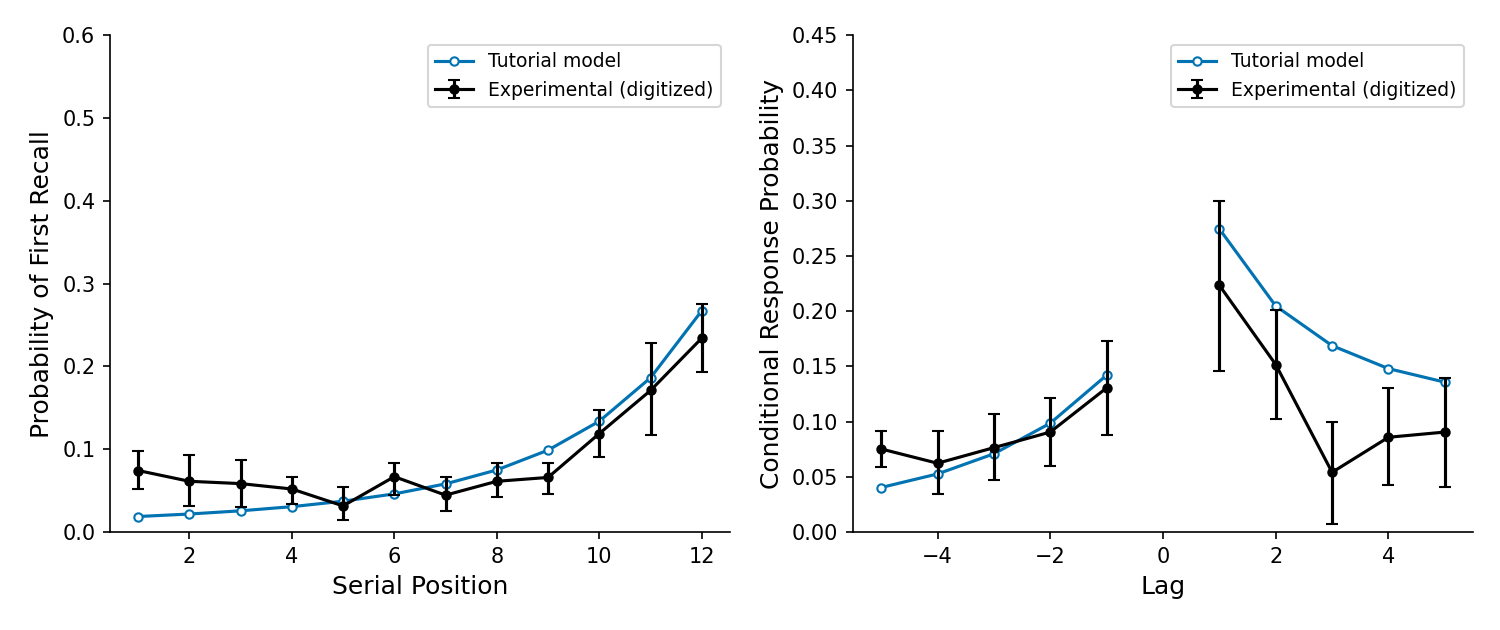

In [9]:
# @title Recall across conditions
time_condition = widgets.Dropdown(options=[(title, key) for key, title in TITLES.items()], value='delayed', description='Condition')
time_beta = widgets.FloatSlider(value=.402, min=.2, max=.7, step=.001, readout_format='.3f', description='β', continuous_update=False)
time_tau = widgets.FloatSlider(value=.247, min=.1, max=.6, step=.001, readout_format='.3f', description='τ', continuous_update=False)
time_d = widgets.FloatSlider(value=7.24, min=0, max=15, step=.01, description='d', continuous_update=False)
time_reset = widgets.Button(description='Reset defaults')
time_view = FigureView()

def draw_time(change=None):
    params = Parameters(beta=time_beta.value, tau=time_tau.value, distractor_duration=time_d.value)
    pfr, lags, crp = predict(time_condition.value, params)
    fig = figures.tcm_recall(pfr, lags, crp, time_condition.value)
    time_view.show(fig)

def reset_time(button=None):
    time_beta.value, time_tau.value, time_d.value = PAPER.beta, PAPER.tau, PAPER.distractor_duration
    draw_time()

for control in [time_condition, time_beta, time_tau, time_d]:
    control.observe(draw_time, names='value')
time_reset.on_click(reset_time)
display(time_condition, widgets.VBox([time_beta, time_tau, time_d]), time_reset)
draw_time()

[Paper (PDF)](https://memory.psych.upenn.edu/files/pubs/HowaKaha02.pdf) · [Publisher page](https://doi.org/10.1006/jmps.2001.1388) · [Model code](https://github.com/h4ch1m1/complementary-learning-systems/blob/main/notebooks/tcm2002/tcm.py)